<a href="https://colab.research.google.com/github/07-khanh/Hands-On-ML/blob/main/11_training_deep_nn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
device = 'cpu'
if torch.cuda.is_available():
  device = 'cuda'
elif torch.backends.mps.is_available():
  device = 'mps'

In [ ]:
layer = nn.Linear(40, 10)
nn.init.kaiming_uniform_(layer.weight)
nn.init.zeros_(layer.bias)

Parameter containing:
tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True)

---

If you want to apply the same initialization method to the weights of every `nn.Linear layer` in a model:
-  Do so in the model’s constructor, after creating each `nn.Linear` layer.
- Write a subclass of the nn.Linear class and tweak its constructor to initialize the weights as you wish.
- But arguably the simplest option is to write a little function that takes a module, checks whether it’s an instance of the `nn.Linear` class, and if so, applies the desired initialization function to its weights. You can then apply this function to the model and all of its submodules by
passing it to the model’s `apply()` method.

---

In [ ]:
def use_he_init(module):
  if isinstance(module, nn.Linear):
    nn.init.kaiming_uniform_(module.weight)
    nn.init.zeros_(module.bias)

model = nn.Sequential(nn.Linear(50, 40), nn.ReLU(), nn.Linear(40, 1), nn.ReLU())
model.apply(use_he_init)

Sequential(
  (0): Linear(in_features=50, out_features=40, bias=True)
  (1): ReLU()
  (2): Linear(in_features=40, out_features=1, bias=True)
  (3): ReLU()
)

---

The `torch.nn.init` module also contains an `orthogonal_()` function which initializes the weights using a random orthogonal matrix.

Orthogonal matrices have a number of useful mathematical properties, including the fact that they preserve norms: given an orthogonal matrix
$W$ and an input vector $x$, the norm of $Wx$ is equal to the norm of $x$, and there
fore the magnitude of the inputs is preserved in the outputs. When the inputs are
standardized, this results in a stable variance through the layer, which prevents the
activations and gradients from vanishing or exploding in a deep network (at least at
the beginning of training).

This initialization technique is much less common than
the initialization techniques discussed earlier as normalization layers and residual connections already guarantee stable signal propagation, gradient updates break orthogonality immediately after step 0, and computing QR/SVD factorizations adds unnecessary computational overhead. However, it can work well in recurrent neural nets or generative adversarial networks.
                   
---

---

In a classifier, it’s generally a good idea to scale down the weights
of the output layer during initialization (e.g., by a factor of 10).

=> smaller logits at the beginning of training -> logits will be closer together -> the estimated probabilities will also be closer together.

=> encourages the model to be less confident about its predictions when
training starts.

This will avoid extreme losses and huge gradients that can often make the model’s weights bounce around randomly at the start of training, losing time and potentially preventing the model from learning anything.

---

---

!!!! In short, scaling the weights properly will give a deep neural net a much better
**starting point** for training.

---

# Better Activation Functions

## Leaky ReLU

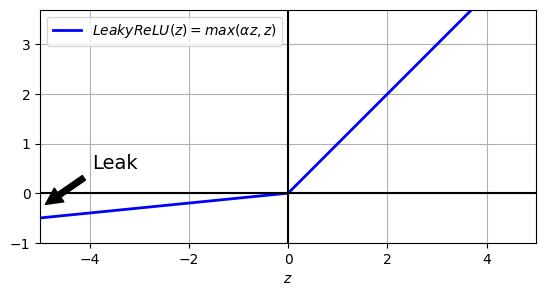

In [ ]:
# extra code – this cell generates Figure 11–2

def leaky_relu(z, alpha):
    return np.maximum(alpha * z, z)

z = np.linspace(-5, 5, 200)
plt.plot(z, leaky_relu(z, 0.1), "b-", linewidth=2, label=r"$LeakyReLU(z) = max(\alpha z, z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([0, 0], [-1, 3.7], 'k-')
plt.grid(True)
props = dict(facecolor='black', shrink=0.1)
plt.annotate('Leak', xytext=(-3.5, 0.5), xy=(-5, -0.3), arrowprops=props,
             fontsize=14, ha="center")
plt.xlabel("$z$")
plt.axis([-5, 5, -1, 3.7])
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [ ]:
alpha = 0.2
model = nn.Sequential(nn.Linear(50, 40), nn.LeakyReLU(negative_slope=alpha))
nn.init.kaiming_uniform_(model[0].weight, alpha, nonlinearity='leaky_relu') # pass in alpha to get the appropriately adjusted Kaiming initialization

Parameter containing:
tensor([[ 0.1447, -0.3003,  0.1211,  ..., -0.0863,  0.2759, -0.1091],
        [-0.2599,  0.0597, -0.2030,  ...,  0.0940,  0.1882, -0.2574],
        [-0.3215, -0.2064,  0.1278,  ..., -0.0732,  0.2819,  0.1080],
        ...,
        [-0.1677,  0.1966,  0.1260,  ...,  0.3134, -0.0413, -0.1243],
        [ 0.1357, -0.0268, -0.1942,  ..., -0.0599,  0.2853, -0.3306],
        [-0.2752, -0.2404,  0.0548,  ...,  0.1238, -0.2117, -0.0296]],
       requires_grad=True)

## ELU

Implementing ELU in PyTorch is trivial, just add an ELU layer after each `Linear` layer in your model, and make sure to use Kaiming initialization for these `Linear` layers:

In [ ]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.ELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

## SELU

By default, the SELU hyperparameters (`scale` and `alpha`) are tuned in such a way that the mean output of each neuron remains close to 0, and the standard deviation remains close to 1 (assuming the inputs are standardized with mean 0 and standard deviation 1 too, and other constraints are respected, as explained in the book). Using this activation function, even a 1,000 layer deep neural network preserves roughly mean 0 and standard deviation 1 across all layers, avoiding the exploding/vanishing gradients problem:

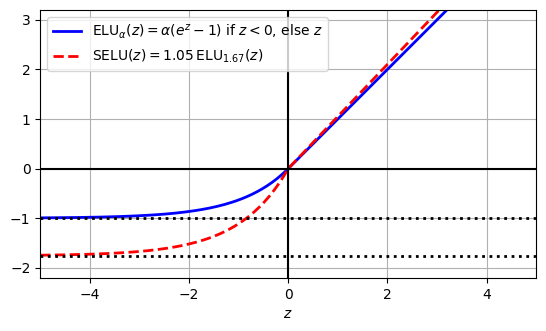

In [ ]:
# extra code – this cell generates Figure 11–3

from scipy.special import erfc

# alpha and scale to self normalize with mean 0 and standard deviation 1
# (see equation 14 in the paper):
alpha_0_1 = -np.sqrt(2 / np.pi) / (erfc(1 / np.sqrt(2)) * np.exp(1 / 2) - 1)
scale_0_1 = (
    (1 - erfc(1 / np.sqrt(2)) * np.sqrt(np.e))
    * np.sqrt(2 * np.pi)
    * (
        2 * erfc(np.sqrt(2)) * np.e ** 2
        + np.pi * erfc(1 / np.sqrt(2)) ** 2 * np.e
        - 2 * (2 + np.pi) * erfc(1 / np.sqrt(2)) * np.sqrt(np.e)
        + np.pi
        + 2
    ) ** (-1 / 2)
)

def elu(z, alpha=1):
    return np.where(z < 0, alpha * (np.exp(z) - 1), z)

def selu(z, scale=scale_0_1, alpha=alpha_0_1):
    return scale * elu(z, alpha)

z = np.linspace(-5, 5, 200)
plt.plot(z, elu(z), "b-", linewidth=2, label=r"ELU$_\alpha(z) = \alpha (e^z - 1)$ if $z < 0$, else $z$")
plt.plot(z, selu(z), "r--", linewidth=2, label=r"SELU$(z) = 1.05 \, $ELU$_{1.67}(z)$")
plt.plot([-5, 5], [0, 0], 'k-')
plt.plot([-5, 5], [-1, -1], 'k:', linewidth=2)
plt.plot([-5, 5], [-1.758, -1.758], 'k:', linewidth=2)
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-5, 5, -2.2, 3.2])
plt.xlabel("$z$")
plt.gca().set_aspect("equal")
plt.legend()

plt.show()

In [ ]:
torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), nn.SELU())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

## GELU, Swish, SwiGLU, Mish, and ReLU²

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

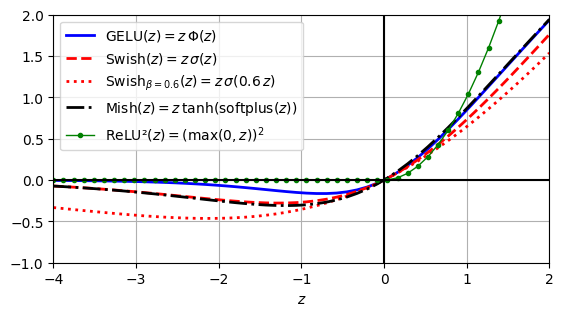

In [ ]:
# extra code – this cell generates Figure 11–4

def swish(z, beta=1):
    return z * sigmoid(beta * z)

def approx_gelu(z):
    return swish(z, beta=1.702)

def softplus(z):
    return np.log(1 + np.exp(z))

def mish(z):
    return z * np.tanh(softplus(z))

def relu_squared(z):
    return np.maximum(0, z)**2

z = np.linspace(-4, 2, 50)

beta = 0.6
plt.plot(z, approx_gelu(z), "b-", linewidth=2,
         label=r"GELU$(z) = z\,\Phi(z)$")
plt.plot(z, swish(z), "r--", linewidth=2,
         label=r"Swish$(z) = z\,\sigma(z)$")
plt.plot(z, swish(z, beta), "r:", linewidth=2,
         label=fr"Swish$_{{\beta={beta}}}(z)=z\,\sigma({beta}\,z)$")
plt.plot(z, mish(z), "k-.", linewidth=2,
         label=fr"Mish$(z) = z\,\tanh($softplus$(z))$")
plt.plot(z, relu_squared(z), "g.-", linewidth=1,
         label=fr"ReLU²$(z) = (\max(0, z))^2$")
plt.plot([-4, 2], [0, 0], 'k-')
plt.plot([0, 0], [-2.2, 3.2], 'k-')
plt.grid(True)
plt.axis([-4, 2, -1, 2])
plt.gca().set_aspect("equal")
plt.xlabel("$z$")
plt.legend(loc="upper left")

plt.show()

### SwiGLU

In [ ]:
class SwiGLU(nn.Module):
    def __init__(self, beta=1.0):
        super().__init__()
        self.beta = beta

    def forward(self, x):
        z1, z2 = x.chunk(2, dim=-1)
        param_swish = z1 * torch.sigmoid(self.beta * z1)
        return param_swish * z2

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 2 * 40), SwiGLU(beta=0.2))
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

### ReLU²

In [ ]:
import torch.nn.functional as F

class ReLU2(nn.Module):
    def forward(self, x):
        return F.relu(x).square()

torch.manual_seed(42)
model = nn.Sequential(nn.Linear(50, 40), ReLU2())
nn.init.kaiming_uniform_(model[0].weight)
model(torch.rand(2, 50)).shape

torch.Size([2, 40])

## Batch Normalization

## Layer Normalization

## Gradient Clipping

# Reusing Pretrained Layers

## Transfer Learning with PyTorch

Let's split the fashion MNIST training set in two:

- `X_train_A`: all images of all items except for T-shirts/tops and pullovers (classes 0 and 2).
- `X_train_B`: a much smaller training set of just the first 20 images of T-shirts/tops and pullovers.
The validation set and the test set are also split this way, but without restricting the number of images.

We will train a model on set A (classification task with 8 classes), and try to reuse it to tackle set B (binary classification). We hope to transfer a little bit of knowledge from task A to task B, since classes in set A (trousers, dresses, coats, sandals, shirts, sneakers, bags, and ankle boots) are somewhat similar to classes in set B (T-shirts/tops and pullovers). However, since we are using `Linear` layers, only patterns that occur at the same location can be reused (in contrast, convolutional layers will transfer much better, since learned patterns can be detected anywhere on the image, as we will see in the chapter 12).

Let's fetch the Fashion MNIST data and split it into datasets A and B:

In [ ]:
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import fetch_openml

fashion_mnist = fetch_openml(name='Fashion-MNIST', as_frame=False)
X = torch.FloatTensor(fashion_mnist.data.reshape(-1, 1, 28, 28) / 255.)
y = torch.from_numpy(fashion_mnist.target.astype(int)) # from_numpy returns a Tensor from a numpy array, with the same memory.

In [ ]:
in_b = (y == 0) | (y == 2) # Pullover or T-shirt/top
X_A, y_A = X[~in_b], y[~in_b]
y_A = torch.maximum(y_A-2, torch.tensor(0)) # [1,3,4,5,6,7,8,9] => [0,..,7]
X_B, y_B = X[in_b], (y[in_b] == 2).to(dtype=torch.float32).view(-1, 1)

In [ ]:
train_set_A = TensorDataset(X_A[:-7_000], y_A[:-7_000])
val_set_A = TensorDataset(X_A[-7_000:-5000], y_A[-7000:-5000])
test_set_A = TensorDataset(X_A[-5_000:], y_A[-5000:])
train_set_B = TensorDataset(X_B[:20], y_B[:20])
val_set_B = TensorDataset(X_B[20:5000], y_B[20:5000])
test_set_B = TensorDataset(X_B[5_000:], y_B[5000:])

train_loader_A = DataLoader(train_set_A, batch_size=32, shuffle=True)
val_loader_A = DataLoader(val_set_A, batch_size=32)
test_loader_A = DataLoader(test_set_A, batch_size=32)
train_loader_B = DataLoader(train_set_B, batch_size=32, shuffle=True)
val_loader_B = DataLoader(val_set_B, batch_size=32)
test_loader_B = DataLoader(test_set_B, batch_size=32)

In [ ]:
%pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 21.4 MB/s eta 0:00:00


In [ ]:
import torchmetrics

def evaluate_tm(model, dataloader, metric):
  model.eval()
  metric.reset()
  with torch.no_grad():
    for X_batch, y_batch in dataloader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      metric.update(y_pred, y_batch)
  return metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, val_loader, n_epochs):
  history = {'train_losses': [], 'train_metrics': [], 'val_metrics': []}
  for epoch in range(n_epochs):
    total_loss = 0.
    model.train()
    metric.reset()
    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      loss = loss_fn(y_pred, y_batch)
      total_loss += loss.item()
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
      metric.update(y_pred, y_batch)
    train_loss = total_loss / len(train_loader)
    history['train_losses'].append(train_loss)
    history['train_metrics'].append(metric.compute().item())
    history['val_metrics'].append(evaluate_tm(model, val_loader, metric).item())
    print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"val metric: {history['val_metrics'][-1]:.4f}")
  return history

Let's define our first model for task A:

In [ ]:
torch.manual_seed(42)

model_A = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1*28*28, 100), nn.ReLU(),
    nn.Linear(100, 100), nn.ReLU(),
    nn.Linear(100, 100), nn.ReLU(),
    nn.Linear(100, 8)
    )
model_A = model_A.to(device)

In [ ]:
model_A.apply(use_he_init)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=100, bias=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=100, bias=True)
  (4): ReLU()
  (5): Linear(in_features=100, out_features=100, bias=True)
  (6): ReLU()
  (7): Linear(in_features=100, out_features=8, bias=True)
)

In [ ]:
n_epochs = 20
xentropy = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model_A.parameters(), lr=0.005)
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=8).to(device)
history_A = train(model_A, optimizer, xentropy, accuracy, train_loader_A, val_loader_A, n_epochs)

Epoch 1/20, train loss: 0.6363, train metric: 0.7845, val metric: 0.8390
Epoch 2/20, train loss: 0.3525, train metric: 0.8790, val metric: 0.8880
Epoch 3/20, train loss: 0.3054, train metric: 0.8943, val metric: 0.8975
Epoch 4/20, train loss: 0.2811, train metric: 0.9007, val metric: 0.8320
Epoch 5/20, train loss: 0.2652, train metric: 0.9073, val metric: 0.8915
Epoch 6/20, train loss: 0.2519, train metric: 0.9125, val metric: 0.8950
Epoch 7/20, train loss: 0.2397, train metric: 0.9162, val metric: 0.8910
Epoch 8/20, train loss: 0.2317, train metric: 0.9194, val metric: 0.9075
Epoch 9/20, train loss: 0.2234, train metric: 0.9224, val metric: 0.9015
Epoch 10/20, train loss: 0.2149, train metric: 0.9248, val metric: 0.9040
Epoch 11/20, train loss: 0.2098, train metric: 0.9276, val metric: 0.9150
Epoch 12/20, train loss: 0.2029, train metric: 0.9286, val metric: 0.8985
Epoch 13/20, train loss: 0.1982, train metric: 0.9305, val metric: 0.9210
Epoch 14/20, train loss: 0.1929, train metric: 

In [ ]:
torch.manual_seed(9)

model_B = nn.Sequential(
    nn.Flatten(),
    nn.Linear(1*28*28, 100), nn.ReLU(),
    nn.Linear(100, 100), nn.ReLU(),
    nn.Linear(100, 100), nn.ReLU(),
    nn.Linear(100, 1) # output one logit (positive class)
    )
model_B = model_B.to(device)

model_B.apply(use_he_init)

n_epochs = 20
xentropy = nn.BCEWithLogitsLoss() # sigmoid + Binary Cross Entropy
optimizer = torch.optim.SGD(model_B.parameters(), lr=0.005)
accuracy = torchmetrics.Accuracy(task='binary').to(device)
history_B = train(model_B, optimizer, xentropy, accuracy, train_loader_B, val_loader_B, n_epochs)

Epoch 1/20, train loss: 1.1117, train metric: 0.4000, val metric: 0.5032
Epoch 2/20, train loss: 0.8887, train metric: 0.4000, val metric: 0.5036
Epoch 3/20, train loss: 0.7477, train metric: 0.4000, val metric: 0.5181
Epoch 4/20, train loss: 0.6618, train metric: 0.4000, val metric: 0.5823
Epoch 5/20, train loss: 0.6067, train metric: 0.4500, val metric: 0.6705
Epoch 6/20, train loss: 0.5684, train metric: 0.6000, val metric: 0.7588
Epoch 7/20, train loss: 0.5382, train metric: 0.7000, val metric: 0.8062
Epoch 8/20, train loss: 0.5149, train metric: 0.9000, val metric: 0.8359
Epoch 9/20, train loss: 0.4962, train metric: 0.9500, val metric: 0.8512
Epoch 10/20, train loss: 0.4804, train metric: 0.9500, val metric: 0.8606
Epoch 11/20, train loss: 0.4671, train metric: 0.9500, val metric: 0.8651
Epoch 12/20, train loss: 0.4553, train metric: 0.9500, val metric: 0.8697
Epoch 13/20, train loss: 0.4448, train metric: 0.9500, val metric: 0.8731
Epoch 14/20, train loss: 0.4348, train metric: 

In [ ]:
evaluate_tm(model_B, test_loader_B, accuracy)

tensor(0.8860, device='cuda:0')

---

We now create a new model `model_B_on_A` that reuses all layers in `model_A` except for the output layer. To do this, we first create a deep copy of the reused layers of `model_A`, then we create `model_B_on_A`, which is an `nn.Sequential model` based on the reused layers of model A, plus a new output layer for task B: it has a single output since task B is binary classification.

---

In [ ]:
import copy

torch.manual_seed(43)
reused_layers = copy.deepcopy(model_A[:-1]) # copy all modules, along with their data and submodules
model_B_on_A = nn.Sequential(
    *reused_layers,
    nn.Linear(100, 1) # new output layer for task B
).to(device)

---

Since the new output layer was initialized randomly, it will make large errors (at least during the first few epochs), so there will be large error gradients that may wreck the reused weights. To avoid this, one approach is to freeze the reused layers during the first few epochs, giving the new layer some time to learn reasonable weights:

---

In [ ]:
for layer in model_B_on_A[:-1]:
  for param in layer.parameters():
    param.requires_grad = False

In [ ]:
n_epochs = 10
xentropy = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_B_on_A.parameters(), lr=0.005)
accuracy = torchmetrics.Accuracy(task='binary').to(device)
history_B = train(model_B_on_A, optimizer, xentropy, accuracy, train_loader_B, val_loader_B, n_epochs)

Epoch 1/10, train loss: 0.8847, train metric: 0.4000, val metric: 0.4723
Epoch 2/10, train loss: 0.7920, train metric: 0.3000, val metric: 0.4886
Epoch 3/10, train loss: 0.7442, train metric: 0.2000, val metric: 0.5600
Epoch 4/10, train loss: 0.7154, train metric: 0.4500, val metric: 0.6145
Epoch 5/10, train loss: 0.6941, train metric: 0.5500, val metric: 0.6424
Epoch 6/10, train loss: 0.6760, train metric: 0.6500, val metric: 0.6562
Epoch 7/10, train loss: 0.6594, train metric: 0.7000, val metric: 0.6733
Epoch 8/10, train loss: 0.6438, train metric: 0.7000, val metric: 0.6948
Epoch 9/10, train loss: 0.6290, train metric: 0.7000, val metric: 0.7169
Epoch 10/10, train loss: 0.6148, train metric: 0.7500, val metric: 0.7434


---

After you have trained the model for a few epochs, you can unfreeze the reused layers (setting `param.requires_grad = True` for all parameters), reduce the learning rate, and continue training to fine-tune the reused layers for task B.

---

In [ ]:
for layer in model_B_on_A[2:]:
  for param in layer.parameters():
    param.requires_grad = True

n_epochs = 20
xentropy = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_B_on_A.parameters(), lr=0.005)
accuracy = torchmetrics.Accuracy(task='binary').to(device)
history_B = train(model_B_on_A, optimizer, xentropy, accuracy, train_loader_B, val_loader_B, n_epochs)

Epoch 1/20, train loss: 0.6011, train metric: 0.7500, val metric: 0.7709
Epoch 2/20, train loss: 0.5841, train metric: 0.7500, val metric: 0.7994
Epoch 3/20, train loss: 0.5680, train metric: 0.7500, val metric: 0.8247
Epoch 4/20, train loss: 0.5528, train metric: 0.7500, val metric: 0.8418
Epoch 5/20, train loss: 0.5384, train metric: 0.8000, val metric: 0.8572
Epoch 6/20, train loss: 0.5246, train metric: 0.8500, val metric: 0.8711
Epoch 7/20, train loss: 0.5115, train metric: 0.8500, val metric: 0.8831
Epoch 8/20, train loss: 0.4990, train metric: 0.9500, val metric: 0.8878
Epoch 9/20, train loss: 0.4871, train metric: 0.9500, val metric: 0.8964
Epoch 10/20, train loss: 0.4757, train metric: 0.9500, val metric: 0.9024
Epoch 11/20, train loss: 0.4648, train metric: 0.9500, val metric: 0.9064
Epoch 12/20, train loss: 0.4544, train metric: 0.9500, val metric: 0.9100
Epoch 13/20, train loss: 0.4444, train metric: 0.9500, val metric: 0.9127
Epoch 14/20, train loss: 0.4348, train metric: 

In [ ]:
evaluate_tm(model_B_on_A, test_loader_B, accuracy)

tensor(0.9312, device='cuda:0')

---

The result may look good for this configuration, but may be much worse if you use other seeds or classes.

It turns out that transfer learning does not work very well with small dense networks, presumably because small networks learn few patterns, and dense networks learn very specific patterns, which are unlikely to be useful for
other tasks. Transfer learning works best with deep convolutional neural networks and with Transformer architectures.

---

# Faster Optimizer

In [ ]:
# extra code – a little function to test an optimizer on Fashion MNIST

train_set = TensorDataset(X[:55_000], y[:55_000])
valid_set = TensorDataset(X[55_000:60_000], y[55_000:60_000])
test_set = TensorDataset(X[60_000:], y[60_000:])

def build_model(seed=42):
    torch.manual_seed(seed)
    model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(28 * 28, 100),
        nn.ReLU(),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Linear(100, 100),
        nn.ReLU(),
        nn.Linear(100, 10)
    ).to(device)
    model.apply(use_he_init)
    return model

def test_optimizer(model, optimizer, n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    accuracy = torchmetrics.Accuracy(task="multiclass", num_classes=10)
    history = train(model, optimizer, xentropy, accuracy.to(device),
                    train_loader, valid_loader, n_epochs)
    return history, evaluate_tm(model, test_loader, accuracy)

In [ ]:
model = build_model()
optimizer = torch.optim.RMSprop(model.parameters(), alpha=0.9, lr=2e-3)
history_rmsprop, acc_rmsprop = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 0.5419, train metric: 0.8039, val metric: 0.8472
Epoch 2/10, train loss: 0.4447, train metric: 0.8474, val metric: 0.8400
Epoch 3/10, train loss: 0.4301, train metric: 0.8547, val metric: 0.8566
Epoch 4/10, train loss: 0.4284, train metric: 0.8580, val metric: 0.8636
Epoch 5/10, train loss: 0.4289, train metric: 0.8579, val metric: 0.8546
Epoch 6/10, train loss: 0.4278, train metric: 0.8630, val metric: 0.8272
Epoch 7/10, train loss: 0.4232, train metric: 0.8634, val metric: 0.8662
Epoch 8/10, train loss: 0.4194, train metric: 0.8659, val metric: 0.8630
Epoch 9/10, train loss: 0.4245, train metric: 0.8674, val metric: 0.8558
Epoch 10/10, train loss: 0.4235, train metric: 0.8684, val metric: 0.8282


In [ ]:
model = build_model()
optimizer = torch.optim.Adam(model.parameters(), betas=(0.9, 0.999), lr=1e-3)
history_adam, acc_adam = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 0.4972, train metric: 0.8200, val metric: 0.8464
Epoch 2/10, train loss: 0.3756, train metric: 0.8625, val metric: 0.8674
Epoch 3/10, train loss: 0.3401, train metric: 0.8758, val metric: 0.8616
Epoch 4/10, train loss: 0.3142, train metric: 0.8836, val metric: 0.8716
Epoch 5/10, train loss: 0.2990, train metric: 0.8889, val metric: 0.8728
Epoch 6/10, train loss: 0.2887, train metric: 0.8930, val metric: 0.8828
Epoch 7/10, train loss: 0.2712, train metric: 0.8987, val metric: 0.8690
Epoch 8/10, train loss: 0.2644, train metric: 0.9014, val metric: 0.8736
Epoch 9/10, train loss: 0.2553, train metric: 0.9040, val metric: 0.8864
Epoch 10/10, train loss: 0.2474, train metric: 0.9080, val metric: 0.8900


In [ ]:
model = build_model()
optimizer = torch.optim.AdamW(model.parameters(), betas=(0.9, 0.999),
                              weight_decay=1e-5, lr=1e-3)
history_adamw, acc_adamw = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 0.4972, train metric: 0.8200, val metric: 0.8464
Epoch 2/10, train loss: 0.3756, train metric: 0.8625, val metric: 0.8674
Epoch 3/10, train loss: 0.3401, train metric: 0.8758, val metric: 0.8616
Epoch 4/10, train loss: 0.3142, train metric: 0.8836, val metric: 0.8716
Epoch 5/10, train loss: 0.2990, train metric: 0.8889, val metric: 0.8728
Epoch 6/10, train loss: 0.2887, train metric: 0.8930, val metric: 0.8828
Epoch 7/10, train loss: 0.2712, train metric: 0.8987, val metric: 0.8690
Epoch 8/10, train loss: 0.2644, train metric: 0.9014, val metric: 0.8736
Epoch 9/10, train loss: 0.2553, train metric: 0.9040, val metric: 0.8864
Epoch 10/10, train loss: 0.2474, train metric: 0.9080, val metric: 0.8900


# Learning Rate Scheduling

In [ ]:
def train_with_scheduler(model, optimizer, loss_fn, metric, train_loader,
                         val_loader, n_epochs, scheduler):
  history = {'train_losses': [], 'train_metrics': [], 'val_metrics': []}
  for epoch in range(n_epochs):
    total_loss = 0.
    model.train()
    metric.reset()
    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      loss = loss_fn(y_pred, y_batch)
      total_loss += loss.item()
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
      metric.update(y_pred, y_batch)
    train_loss = total_loss / len(train_loader)
    history['train_losses'].append(train_loss)
    history['train_metrics'].append(metric.compute().item())
    val_metric = evaluate_tm(model, val_loader, metric).item()
    history['val_metrics'].append(val_metric)
    print(f"Epoch {epoch + 1}/{n_epochs}, "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.4f}, "
              f"val metric: {history['val_metrics'][-1]:.4f}")
    if isinstance(scheduler, torch.optim.lr_scheduler.ReduceLROnPlateau):
            scheduler.step(val_metric)
    else:
        scheduler.step()
    print(f"Learning rate: {scheduler.get_last_lr()[0]:.5f}")
  return history

def test_scheduler(model, optimizer, scheduler, n_epochs=10, batch_size=32):
    train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
    valid_loader = DataLoader(valid_set, batch_size=32)
    test_loader = DataLoader(test_set, batch_size=32)
    xentropy = nn.CrossEntropyLoss()
    metric = torchmetrics.Accuracy(task="multiclass", num_classes=10).to(device)
    history = train_with_scheduler(
        model, optimizer, xentropy, metric, train_loader, valid_loader,
        n_epochs, scheduler)
    return history, evaluate_tm(model, test_loader, metric)

# Avoiding Overfitting Through Regularization

## ℓ₁ and ℓ₂ regularization

---

ℓ2 regularization is mathematically equivalent to weight
decay when using an SGD optimizer (with or without momentum)

---

In [ ]:
model = build_model()
optimizer = torch.optim.SGD(model.parameters(), lr=0.05, weight_decay=1e-4)
history = test_optimizer(model, optimizer)

Epoch 1/10, train loss: 0.5705, train metric: 0.7923, val metric: 0.8528
Epoch 2/10, train loss: 0.4025, train metric: 0.8528, val metric: 0.8410
Epoch 3/10, train loss: 0.3616, train metric: 0.8663, val metric: 0.8688
Epoch 4/10, train loss: 0.3377, train metric: 0.8747, val metric: 0.8734
Epoch 5/10, train loss: 0.3189, train metric: 0.8828, val metric: 0.8766
Epoch 6/10, train loss: 0.3050, train metric: 0.8865, val metric: 0.8714
Epoch 7/10, train loss: 0.2927, train metric: 0.8907, val metric: 0.8780
Epoch 8/10, train loss: 0.2823, train metric: 0.8946, val metric: 0.8846
Epoch 9/10, train loss: 0.2745, train metric: 0.8972, val metric: 0.8788
Epoch 10/10, train loss: 0.2641, train metric: 0.9015, val metric: 0.8666


---

Note that weight decay is applied to every model parameter, including bias terms, and even parameters of batch-norm and layer-norm layers. Generally that’s not a big deal, but penalizing these parameters does not contribute much to regularization and it may sometimes negatively impact training performance. So how can we apply weight decay to some model parameters and not others?

1. Implement ℓ2 regularization manually, without relying on the optimizer’s weight decay feature. For this, you must tweak the training loop to manually compute the ℓ2 loss based only on the parameters you want, and add this ℓ2 loss to the main loss:

---

In [ ]:
n_epochs = 3
model = build_model()
loss_fn = nn.CrossEntropyLoss()
train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
optimizer = torch.optim.SGD(model.parameters(), lr=0.05)
param_to_regularize = [
    param for name, param in model.named_parameters()
    if not 'bias' in name and not 'bn' in name
]

for epoch in range(n_epochs):
    total_loss = 0.
    total_l2_loss = 0.0
    model.train()
    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      main_loss = loss_fn(y_pred, y_batch)
      l2_loss = sum(param.pow(2.).sum() for param in param_to_regularize)
      loss = main_loss + 1e-4 * l2_loss
      total_loss += loss.item()
      total_l2_loss += l2_loss
      loss.backward()
      optimizer.step()
      optimizer.zero_grad()
    train_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/{n_epochs}"
          f" – l2 loss: {total_l2_loss / len(train_loader):.3f}"
          f" – loss: {total_loss / len(train_loader):.3f}")

Epoch 1/3 – l2 loss: 637.471 – loss: 0.634
Epoch 2/3 – l2 loss: 647.277 – loss: 0.467
Epoch 3/3 – l2 loss: 649.364 – loss: 0.427


---

2. Use PyTorch’s parameter groups feature, which lets the optimizer apply different hyperparameters to different groups of model parameters.

---

In [ ]:
params_bias_and_bn = [
    param for name, param in model.named_parameters()
    if 'bias' in name or 'bn' in name
]

optimizer = torch.optim.SGD([
    {'params': param_to_regularize, 'weight_decay': 1e-4},
    {'params': params_bias_and_bn},
    ], lr=0.05
)

# then train normally

In [ ]:
params_bias_and_bn

[Parameter containing:
 tensor([-1.0273e-02,  3.7943e-01,  3.8731e-02,  1.0512e-01, -1.2094e-02,
         -9.9531e-02,  2.2852e-04,  2.3125e-01, -1.3729e-02, -1.7718e-02,
         -3.6211e-01,  2.5234e-01,  2.2676e-01,  2.8526e-01, -7.8610e-02,
          4.9781e-02,  1.6241e-02,  1.9362e-02,  1.1552e-03,  2.7348e-02,
         -7.0628e-02,  9.4704e-02,  4.1432e-01,  1.0502e-01,  1.0450e-01,
          3.4083e-01,  1.1305e-01,  5.3663e-02, -3.3837e-02,  1.5315e-01,
          6.0041e-02, -1.5552e-01,  2.0797e-01,  8.8420e-02, -1.4017e-03,
          1.5730e-01, -1.1473e-01,  3.3309e-01, -4.1038e-02,  2.4016e-01,
          2.4183e-01,  3.7928e-01, -1.1007e-01,  1.1328e-01,  2.2318e-02,
          1.8655e-01, -1.6763e-01,  7.9626e-02,  5.1894e-02,  3.5320e-02,
          1.6420e-01,  2.5667e-01,  1.2849e-01,  1.3761e-02, -6.4052e-02,
          3.4283e-02, -7.5095e-02, -2.4696e-02,  2.3231e-01, -2.7742e-02,
          3.9126e-02, -1.6650e-01,  3.1538e-01,  4.2090e-02,  5.8918e-02,
          3.340

## Dropout

In [ ]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Flatten(),
    nn.Dropout(p=0.2), nn.Linear(28 * 28, 100), nn.ReLU(),
    nn.Dropout(p=0.2), nn.Linear(100, 100), nn.ReLU(),
    nn.Dropout(p=0.2), nn.Linear(100, 10)
).to(device)
model.apply(use_he_init)
optimizer = torch.optim.SGD(model.parameters(), lr=0.01, momentum=0.9)
history_dropout, acc_dropout = test_optimizer(model, optimizer, batch_size=32)

Epoch 1/10, train loss: 0.6795, train metric: 0.7514, val metric: 0.8384
Epoch 2/10, train loss: 0.5101, train metric: 0.8142, val metric: 0.8498
Epoch 3/10, train loss: 0.4735, train metric: 0.8267, val metric: 0.8582
Epoch 4/10, train loss: 0.4560, train metric: 0.8330, val metric: 0.8570
Epoch 5/10, train loss: 0.4372, train metric: 0.8394, val metric: 0.8576
Epoch 6/10, train loss: 0.4255, train metric: 0.8445, val metric: 0.8710
Epoch 7/10, train loss: 0.4154, train metric: 0.8473, val metric: 0.8668
Epoch 8/10, train loss: 0.4071, train metric: 0.8498, val metric: 0.8740
Epoch 9/10, train loss: 0.3989, train metric: 0.8513, val metric: 0.8688
Epoch 10/10, train loss: 0.3937, train metric: 0.8556, val metric: 0.8738


## Monte Carlo Dropout

In [ ]:
model.eval()
for module in model.modules():
  if isinstance(module, nn.Dropout):
    module.train()

X_new = torch.FloatTensor(fashion_mnist.data[:3].reshape(3, 1, 28, 28) / 255).to(device)

torch.manual_seed(42)
with torch.no_grad():
  X_new_repeated = X_new.repeat_interleave(100, dim=0)
  y_logits_all = model(X_new_repeated).reshape(3, 100, 10)
  y_probas_all = torch.nn.functional.softmax(y_logits_all, dim=-1)
  y_probas = y_probas_all.mean(dim=1)



In [ ]:
y_probas.round(decimals=2)

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000,
         0.9900],
        [0.9900, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0100, 0.0000, 0.0000,
         0.0000],
        [0.4100, 0.0400, 0.0400, 0.2300, 0.0400, 0.0000, 0.2300, 0.0000, 0.0100,
         0.0000]], device='cuda:0')

In [ ]:
y_probas_all.std(dim=1).round(decimals=2)

tensor([[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0200, 0.0000,
         0.0200],
        [0.0200, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0200, 0.0000, 0.0000,
         0.0000],
        [0.1700, 0.0300, 0.0300, 0.1300, 0.0500, 0.0000, 0.0900, 0.0000, 0.0100,
         0.0000]], device='cuda:0')

# Exercise

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [ ]:
import torchvision
import torchvision.transforms.v2 as T

In [ ]:
device = 'cpu'
if torch.cuda.is_available():
  device = 'cuda'
elif torch.backends.mps.is_available():
  device = 'mps'

In [ ]:
toTensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])

In [ ]:
train_and_val_set = torchvision.datasets.CIFAR10(root='datasets', train=True,
                                                 transform=toTensor, download=True)
test_set = torchvision.datasets.CIFAR10(root='datasets', train=False,
                                                 transform=toTensor, download=True)

100%|██████████| 170M/170M [53:56<00:00, 52.7kB/s]


In [ ]:
torch.manual_seed(42)
train_set, val_set = torch.utils.data.random_split(train_and_val_set,
                                                   lengths=[45_000, 5_000])

In [ ]:
from torch.utils.data import DataLoader

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

In [ ]:
def use_he_init(module):
  if isinstance(module, nn.Linear):
    nn.init.kaiming_uniform_(module.weight)
    nn.init.zeros_(module.bias)

In [ ]:
def build_model(n_inputs, n_hidden, n_neurons, n_classes):
  layers = [nn.Flatten(), nn.Linear(n_inputs, n_neurons), nn.SiLU()]

  for _ in range(n_hidden-1):
    layers += [nn.Linear(n_neurons, n_neurons), nn.SiLU()]

  layers += [nn.Linear(n_neurons, n_classes)]

  model = nn.Sequential(*layers)
  model.apply(use_he_init)

  return model

In [ ]:
class EarlyStopping:
  def __init__(self, patience=5, min_delta=1e-3, path='best_model.pt'):
    self.patience = patience
    self.min_delta = min_delta
    self.path = path
    self.best_val_metric = 0.0
    self.counter = 0
    self.early_stop = False

  def __call__(self, val_metric, model):
      if val_metric > self.best_val_metric + self.min_delta:
          self.best_val_metric = val_metric
          self.counter = 0
          self.save_checkpoint(model)
      else:
        self.counter += 1
        if self.counter >= self.patience:
          self.early_stop = True

  def save_checkpoint(self, model):
    torch.save(model.state_dict(), self.path)

  def load_best_weights(self, model):
    model.load_state_dict(torch.load(self.path, weights_only=True))


In [ ]:
def evaluate_tm(model, dataloader, metric):
  model.eval()
  metric.reset()
  with torch.no_grad():
    for X_batch, y_batch in dataloader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      metric.update(y_pred, y_batch)
  return metric.compute()

In [ ]:
def train(model, optimizer, loss_fn, metric, train_loader, val_loader, n_epochs,
          early_stopping, scheduler=None):

  history = {'train_loss': [], 'train_metric': [], 'val_metric': []}
  best_val_metric = 0.0

  for epoch in range(n_epochs):
    total_loss = 0.0
    metric.reset()
    model.train()

    for X_batch, y_batch in train_loader:
      X_batch, y_batch = X_batch.to(device), y_batch.to(device)
      y_pred = model(X_batch)
      loss = loss_fn(y_pred, y_batch)

      loss.backward()
      optimizer.step()
      if scheduler is not None:
        scheduler.step()
      optimizer.zero_grad()

      metric.update(y_pred, y_batch)
      total_loss += loss.item()

    train_loss = total_loss / len(train_loader)
    train_metric = metric.compute().item()
    val_metric = evaluate_tm(model, val_loader, metric).item()

    history['train_loss'].append(train_loss)
    history['train_metric'].append(train_metric)
    history['val_metric'].append(val_metric)

    print(f'Epoch: {epoch+1}/{n_epochs} | '
          f'Train loss: {train_loss:.4f} | ',
          f'Train Metric: {train_metric:.4f} | ',
          f'Val Metric: {val_metric:.4f}')

    early_stopping(val_metric, model)
    if early_stopping.early_stop:
      print(f'Early stopping at epoch {epoch+1}|{n_epochs}')
      break

  return history

In [ ]:
%pip install torchmetrics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 31.4 MB/s eta 0:00:00


In [ ]:
import torchmetrics

In [ ]:
n_inputs = 32 * 32 * 3
n_hidden = 20
n_neurons = 100
n_classes = 10
n_epochs = 100

model = build_model(n_inputs, n_hidden, n_neurons, n_classes).to(device)
optimizer = torch.optim.NAdam(model.parameters(), lr=1e-3)
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=n_classes).to(device)
early_stopping = EarlyStopping(patience=20, min_delta=1e-3, path='best_model.pt')
xentropy = nn.CrossEntropyLoss()

history = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs, early_stopping)

Epoch: 1/100 | Train loss: 2.1807 |  Train Metric: 0.1632 |  Val Metric: 0.1906
Epoch: 2/100 | Train loss: 2.0394 |  Train Metric: 0.2220 |  Val Metric: 0.2472
Epoch: 3/100 | Train loss: 1.9872 |  Train Metric: 0.2435 |  Val Metric: 0.2768
Epoch: 4/100 | Train loss: 1.8971 |  Train Metric: 0.2816 |  Val Metric: 0.2732
Epoch: 5/100 | Train loss: 1.8430 |  Train Metric: 0.3109 |  Val Metric: 0.3178
Epoch: 6/100 | Train loss: 1.8041 |  Train Metric: 0.3330 |  Val Metric: 0.3406
Epoch: 7/100 | Train loss: 1.7755 |  Train Metric: 0.3442 |  Val Metric: 0.3516
Epoch: 8/100 | Train loss: 1.7441 |  Train Metric: 0.3595 |  Val Metric: 0.3460
Epoch: 9/100 | Train loss: 1.7197 |  Train Metric: 0.3702 |  Val Metric: 0.3438
Epoch: 10/100 | Train loss: 1.7067 |  Train Metric: 0.3807 |  Val Metric: 0.3840
Epoch: 11/100 | Train loss: 1.6794 |  Train Metric: 0.3885 |  Val Metric: 0.3932
Epoch: 12/100 | Train loss: 1.6633 |  Train Metric: 0.3968 |  Val Metric: 0.3930
Epoch: 13/100 | Train loss: 1.6476 | 

In [ ]:
early_stopping.best_val_metric

0.42980000376701355

In [ ]:
def build_model_with_bn(n_inputs, n_hidden, n_neurons, n_classes):
  layers = [nn.Flatten(), nn.Linear(n_inputs, n_neurons), nn.BatchNorm1d(n_neurons), nn.SiLU()]

  for _ in range(n_hidden-1):
    layers += [nn.Linear(n_neurons, n_neurons), nn.BatchNorm1d(n_neurons), nn.SiLU()]

  layers += [nn.Linear(n_neurons, n_classes)]

  model = nn.Sequential(*layers)
  model.apply(use_he_init)

  return model

In [ ]:
model = build_model_with_bn(n_inputs, n_hidden, n_neurons, n_classes).to(device)
optimizer = torch.optim.NAdam(model.parameters(), lr=2e-3)
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=n_classes).to(device)
early_stopping = EarlyStopping(patience=5, min_delta=1e-3, path='best_model.pt')
xentropy = nn.CrossEntropyLoss()

history_bn = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs, early_stopping)

In [ ]:
early_stopping.best_val_metric

In [ ]:
def use_lecun_init(module):
    if isinstance(module, nn.Linear):
        nn.init.normal_(
            module.weight,
            mean = 0.0,
            std = 1.0 / (module.in_features)**0.5
        )
        nn.init.zeros_(module.bias)

In [ ]:
class Standard(nn.Module):
    def __init__(self, sample):
        super().__init__()
        flat = torch.flatten(sample, start_dim=1)
        mean = flat.mean(dim=0, keepdim=True)
        std = flat.std(dim=0, keepdim=True)
        self.register_buffer('mean', mean)
        self.register_buffer('std', std)

    def forward(self, X):
        return (X - self.mean) / self.std



In [ ]:
all_images = torch.stack([img for img, _ in train_set])
standardize = Standard(all_images)

In [ ]:
def build_self_norm_model(n_inputs, n_hidden, n_neurons, n_classes):
  layers = [nn.Flatten(), standardize, nn.Linear(n_inputs, n_neurons), nn.SELU()]

  for _ in range(n_hidden-1):
    layers += [nn.Linear(n_neurons, n_neurons), nn.SELU()]

  layers += [nn.Linear(n_neurons, n_classes)]

  model = nn.Sequential(*layers)
  model.apply(use_lecun_init)

  return model

In [ ]:
model = build_self_norm_model(n_inputs, n_hidden, n_neurons, n_classes).to(device)
optimizer = torch.optim.NAdam(model.parameters(), lr=1e-3)
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=n_classes).to(device)
early_stopping = EarlyStopping(patience=5, min_delta=1e-3, path='best_model.pt')
xentropy = nn.CrossEntropyLoss()

history_self_norm = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs, early_stopping)


In [ ]:
early_stopping.best_val_metric

In [ ]:
def build_with_alpha_dropout(n_inputs, n_hidden, n_neurons, n_classes, dropout_rate=0.5):
  layers = [nn.Flatten(), standardize, nn.Linear(n_inputs, n_neurons), nn.SELU(),
            nn.AlphaDropout(dropout_rate)]

  for _ in range(n_hidden-1):
    layers += [nn.Linear(n_neurons, n_neurons), nn.SELU(),
               nn.AlphaDropout(dropout_rate)]

  layers += [nn.Linear(n_neurons, n_classes)]

  model = nn.Sequential(*layers)
  model.apply(use_lecun_init)

  return model


In [ ]:
model = build_with_alpha_dropout(n_inputs, n_hidden, n_neurons, n_classes, dropout_rate=0.1).to(device)
optimizer = torch.optim.NAdam(model.parameters(), lr=1e-3)
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=n_classes).to(device)
early_stopping = EarlyStopping(patience=7, min_delta=1e-3, path='best_model.pt')
xentropy = nn.CrossEntropyLoss()

history_self_norm = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs, early_stopping)

In [ ]:
early_stopping.best_val_metric

In [ ]:
model = build_with_alpha_dropout(n_inputs, n_hidden, n_neurons, n_classes, dropout_rate=0.1).to(device)
optimizer = torch.optim.NAdam(model.parameters(), lr=1e-3)
accuracy = torchmetrics.Accuracy(task='multiclass', num_classes=n_classes).to(device)
early_stopping = EarlyStopping(patience=20, min_delta=1e-3, path='best_model.pt')
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=1e-2, epochs=n_epochs, steps_per_epoch=len(train_loader))
xentropy = nn.CrossEntropyLoss()

history_self_norm = train(model, optimizer, xentropy, accuracy, train_loader, val_loader,
                n_epochs, early_stopping, scheduler)